# Classification Track — Notebook 14
# 9. Train All Five Models · 10. Comparison · 11. Analysis · 12. Conclusion

**Input:** `artifacts/clf_13_split.joblib`
**Output:** `artifacts/clf_14_results.joblib`, `outputs/clf_model_comparison.csv`

---

### Purpose

Train the five required Part-A algorithms on the identical stratified split
from Notebook 13, evaluate them with identical code, and analyse what the
results mean — including what the errors mean for a real person.

### How fairness is guaranteed

| Requirement | Mechanism |
|---|---|
| Same split | Loaded from `clf_13_split`; never re-split |
| Same target encoding | `>50K` = 1 for every model |
| Same preprocessing | Each model wraps a **clone** of the same `ColumnTransformer` |
| Same metrics code | All five go through `evaluate_classifier()` in `ml_utils.py` |
| No leakage | Preprocessing lives inside each `Pipeline`, fitted on train only |

All five use scikit-learn defaults plus `random_state=42`, so this is an
out-of-the-box comparison. (Tuning of the classification track is Review 2
work; the Review 1 rubric asks for implementation and evaluation here.)

In [1]:
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree


def find_src_folder() -> Path:
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "src" / "ml_utils.py").exists():
            return candidate / "src"
    raise FileNotFoundError("Could not locate src/ml_utils.py — check the repo layout.")


sys.path.insert(0, str(find_src_folder()))

from ml_utils import (  # noqa: E402
    RANDOM_STATE,
    evaluate_classifier,
    load_artifact,
    plot_confusion_matrix,
    rank_results,
    save_artifact,
    save_figure,
    save_table,
    section,
    set_plot_style,
)

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
set_plot_style()

bundle = load_artifact("clf_13_split")
X_train, X_test = bundle["X_train"], bundle["X_test"]
y_train, y_test = bundle["y_train"], bundle["y_test"]
preprocessor = bundle["preprocessor"]
CLASS_LABELS = bundle["class_labels"]        # ['<=50K', '>50K']

section("FROZEN SPLIT")
print(f"X_train : {X_train.shape}")
print(f"X_test  : {X_test.shape}")
print(f"Test class balance: {dict(y_test.value_counts().sort_index())}")


def build_pipeline(model):
    """Wrap a classifier in a fresh clone of the shared preprocessing pipeline."""
    return Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("model", model),
    ])


results = []
confusion_matrices = {}
predictions = {}
fitted_models = {}

[loaded] artifacts/clf_13_split.joblib
FROZEN SPLIT
X_train : (39073, 20)
X_test  : (9769, 20)
Test class balance: {0: np.int64(7431), 1: np.int64(2338)}


---
## 9.0 The baseline every model must beat

Notebook 11 §3.5 showed that a model predicting `<=50K` for everyone scores
about 76% accuracy while learning nothing. We compute it on this exact test
set so the comparison is like-for-like.

In [2]:
dummy = build_pipeline(DummyClassifier(strategy="most_frequent"))
dummy_row, dummy_cm, _ = evaluate_classifier("Baseline (always <=50K)", dummy,
                                             X_train, y_train, X_test, y_test)

section("MAJORITY-CLASS BASELINE")
print(f"Accuracy    : {dummy_row['Accuracy']:.4f}")
print(f"Weighted F1 : {dummy_row['Weighted F1']:.4f}")
print(f"F1 on >50K  : {dummy_row['F1 (>50K class)']:.4f}")
print("\nEvery model below must clear these numbers to have learned anything.")

MAJORITY-CLASS BASELINE
Accuracy    : 0.7607
Weighted F1 : 0.6573
F1 on >50K  : 0.0000

Every model below must clear these numbers to have learned anything.


---
## Model 1 — Logistic Regression

A linear model that estimates the **log-odds** of the positive class as a
weighted sum of the features, then squashes it through the sigmoid function
into a probability between 0 and 1. It predicts `>50K` when that probability
exceeds 0.5.

Its coefficients are directly interpretable as log-odds, which makes it the
natural baseline classifier. Its limitation is the mirror image of Linear
Regression's in the regression track: it fits a single weight per feature and
therefore cannot represent the non-monotonic age effect from EDA §4.5 or the
interactions from §4.7. The banded features added in Notebook 13 §6.3–6.4
partly compensate.

`max_iter=1000` is raised above the default of 100 because the default does
not converge on 88 features.

In [3]:
t0 = time.time()
pipe = build_pipeline(LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
row, cm, y_pred = evaluate_classifier("Logistic Regression", pipe,
                                      X_train, y_train, X_test, y_test)
results.append(row)
confusion_matrices["Logistic Regression"] = cm
predictions["Logistic Regression"] = y_pred
fitted_models["Logistic Regression"] = pipe
print(f"Accuracy = {row['Accuracy']:.4f} | Weighted F1 = {row['Weighted F1']:.4f} "
      f"| {time.time() - t0:.1f}s")

Accuracy = 0.8589 | Weighted F1 = 0.8538 | 0.6s


---
## Model 2 — K-Nearest Neighbors

Stores the training data and classifies a new person by majority vote among
their `k` nearest neighbours in feature space (`k=5` by default). It assumes
nothing about functional form at all.

**Scaling is essential**, as argued in Notebook 13 §8.2 — without it the
neighbours would be determined almost entirely by `capital-gain`. EDA §4.3
also warned that ~88 mostly-sparse one-hot columns will blunt the distance
metric, so we expect KNN to be competitive rather than dominant.

In [4]:
t0 = time.time()
pipe = build_pipeline(KNeighborsClassifier())    # default k = 5
row, cm, y_pred = evaluate_classifier("K-Nearest Neighbors", pipe,
                                      X_train, y_train, X_test, y_test)
results.append(row)
confusion_matrices["K-Nearest Neighbors"] = cm
predictions["K-Nearest Neighbors"] = y_pred
fitted_models["K-Nearest Neighbors"] = pipe
print(f"Accuracy = {row['Accuracy']:.4f} | Weighted F1 = {row['Weighted F1']:.4f} "
      f"| {time.time() - t0:.1f}s")

Accuracy = 0.8410 | Weighted F1 = 0.8385 | 10.9s


---
## Model 3 — Gaussian Naive Bayes

Applies Bayes' theorem with a strong simplifying assumption: that **every
feature is conditionally independent of every other, given the class**, and
that each numeric feature is normally distributed within each class.

Both assumptions are demonstrably false here, and EDA §4.7 showed exactly why:
age and hours interact, education and sex interact, and `relationship` largely
restates `marital-status`. Nor are the one-hot columns remotely Gaussian —
they take only the values 0 and 1.

This gives us a **falsifiable prediction**: Naive Bayes should be the weakest
of the five. The result below tests it.

In [5]:
t0 = time.time()
pipe = build_pipeline(GaussianNB())
row, cm, y_pred = evaluate_classifier("Gaussian Naive Bayes", pipe,
                                      X_train, y_train, X_test, y_test)
results.append(row)
confusion_matrices["Gaussian Naive Bayes"] = cm
predictions["Gaussian Naive Bayes"] = y_pred
fitted_models["Gaussian Naive Bayes"] = pipe
print(f"Accuracy = {row['Accuracy']:.4f} | Weighted F1 = {row['Weighted F1']:.4f} "
      f"| {time.time() - t0:.1f}s")

Accuracy = 0.6752 | Weighted F1 = 0.6983 | 0.3s


---
## Model 4 — Decision Tree Classifier

Recursively splits the data on the feature that best separates the classes,
measured by Gini impurity. It models interactions **natively** — a split on
`age` followed by a split on `hours-per-week` within that branch *is* an
interaction — and it is scale-invariant.

Left at the default `max_depth=None` it grows until every leaf is pure, which
is exactly what overfitting looks like. We keep the default here so the
overfitting is measurable rather than hidden.

In [6]:
t0 = time.time()
pipe = build_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE))
row, cm, y_pred = evaluate_classifier("Decision Tree", pipe,
                                      X_train, y_train, X_test, y_test)
results.append(row)
confusion_matrices["Decision Tree"] = cm
predictions["Decision Tree"] = y_pred
fitted_models["Decision Tree"] = pipe
print(f"Accuracy = {row['Accuracy']:.4f} | Weighted F1 = {row['Weighted F1']:.4f} "
      f"| {time.time() - t0:.1f}s")

tree_model = pipe.named_steps["model"]
print(f"\nTree depth      : {tree_model.get_depth()}")
print(f"Leaf nodes      : {tree_model.get_n_leaves():,}")
print(f"Train accuracy  : {row['Train Accuracy']:.4f}")
print(f"Test accuracy   : {row['Accuracy']:.4f}")
print(f"Overfitting gap : {row['Overfit gap (Train − Test Acc)']:.4f}")

Accuracy = 0.8265 | Weighted F1 = 0.8258 | 0.6s

Tree depth      : 51
Leaf nodes      : 6,699
Train accuracy  : 0.9748
Test accuracy   : 0.8265
Overfitting gap : 0.1483


---
## Model 5 — Support Vector Classifier (SVC)

Finds the decision boundary that maximises the **margin** between the two
classes. With the RBF kernel it can form a highly non-linear boundary by
implicitly mapping the data into a higher-dimensional space.

**Requires scaled features** — the RBF kernel is a function of Euclidean
distance (Notebook 13 §8.2). Unlike SVR in the regression track, the
classification defaults (`C=1.0`, `gamma='scale'`) are well suited to this
problem, because a classifier's output is a class label rather than a quantity
whose magnitude has to match the target's scale. We should therefore **not**
expect the dramatic default-vs-tuned gap that SVR showed.

SVC is the slowest of the five: its training cost grows roughly quadratically
with the number of rows, and we have 39,073.

In [7]:
t0 = time.time()
pipe = build_pipeline(SVC(random_state=RANDOM_STATE, cache_size=1000))
row, cm, y_pred = evaluate_classifier("Support Vector Classifier", pipe,
                                      X_train, y_train, X_test, y_test)
results.append(row)
confusion_matrices["Support Vector Classifier"] = cm
predictions["Support Vector Classifier"] = y_pred
fitted_models["Support Vector Classifier"] = pipe
print(f"Accuracy = {row['Accuracy']:.4f} | Weighted F1 = {row['Weighted F1']:.4f} "
      f"| {time.time() - t0:.0f}s")
print(f"Support vectors: {pipe.named_steps['model'].support_.shape[0]:,} "
      f"of {len(X_train):,} training rows")

Accuracy = 0.8591 | Weighted F1 = 0.8520 | 86s
Support vectors: 13,191 of 39,073 training rows


---
## 9.1 Consolidated comparison table

In [8]:
results_df = rank_results(results, by="Weighted F1", ascending=False)

comparison_table = results_df[["Rank", "Model", "Accuracy", "Weighted F1"]].copy()
comparison_table[["Accuracy", "Weighted F1"]] = comparison_table[
    ["Accuracy", "Weighted F1"]].round(4)

save_table(comparison_table, "clf_model_comparison")

section("REQUIRED COMPARISON TABLE — ALL 5 CLASSIFIERS (test set)")
print(comparison_table.to_string(index=False))
print(f"\n(Baseline for reference: Accuracy {dummy_row['Accuracy']:.4f}, "
      f"Weighted F1 {dummy_row['Weighted F1']:.4f})")

[saved]  outputs/clf_model_comparison.csv
REQUIRED COMPARISON TABLE — ALL 5 CLASSIFIERS (test set)
 Rank                     Model  Accuracy  Weighted F1
    1       Logistic Regression    0.8589       0.8538
    2 Support Vector Classifier    0.8591       0.8520
    3       K-Nearest Neighbors    0.8410       0.8385
    4             Decision Tree    0.8265       0.8258
    5      Gaussian Naive Bayes    0.6752       0.6983

(Baseline for reference: Accuracy 0.7607, Weighted F1 0.6573)


In [9]:
comparison_table

,Rank,Model,Accuracy,Weighted F1
0,1,Logistic Regression,0.8589,0.8538
1,2,Support Vector Classifier,0.8591,0.8520
2,3,K-Nearest Neighbors,0.8410,0.8385
3,4,Decision Tree,0.8265,0.8258
4,5,Gaussian Naive Bayes,0.6752,0.6983


### The same models with the additional metrics

Accuracy and weighted F1 are the required headline metrics. Precision and
recall on the **minority class** are shown alongside because, with a 76/24
imbalance, they reveal behaviour the headline numbers average away.

In [10]:
detail_table = results_df[[
    "Rank", "Model", "Accuracy", "Weighted F1",
    "Weighted Precision", "Weighted Recall",
    "Precision (>50K class)", "Recall (>50K class)", "F1 (>50K class)",
    "Train Accuracy", "Overfit gap (Train − Test Acc)",
]].round(4)

section("DETAILED METRICS")
print(detail_table.to_string(index=False))
save_table(detail_table, "clf_model_comparison_detailed")

DETAILED METRICS
 Rank                     Model  Accuracy  Weighted F1  Weighted Precision  Weighted Recall  Precision (>50K class)  Recall (>50K class)  F1 (>50K class)  Train Accuracy  Overfit gap (Train − Test Acc)
    1       Logistic Regression    0.8589       0.8538              0.8531           0.8589                  0.7518               0.6129           0.6753          0.8600                          0.0010
    2 Support Vector Classifier    0.8591       0.8520              0.8529           0.8591                  0.7721               0.5838           0.6649          0.8640                          0.0049
    3       K-Nearest Neighbors    0.8410       0.8385              0.8369           0.8410                  0.6837               0.6249           0.6530          0.8825                          0.0415
    4             Decision Tree    0.8265       0.8258              0.8251           0.8265                  0.6409               0.6253           0.6330          0.9748      

PosixPath('/home/claude/project/outputs/clf_model_comparison_detailed.csv')

### Per-class reports

In [11]:
for name in results_df["Model"]:
    section(f"CLASSIFICATION REPORT — {name}")
    print(classification_report(y_test, predictions[name],
                                target_names=CLASS_LABELS, digits=4,
                                zero_division=0))

CLASSIFICATION REPORT — Logistic Regression
              precision    recall  f1-score   support

       <=50K     0.8849    0.9363    0.9099      7431
        >50K     0.7518    0.6129    0.6753      2338

    accuracy                         0.8589      9769
   macro avg     0.8184    0.7746    0.7926      9769
weighted avg     0.8531    0.8589    0.8538      9769

CLASSIFICATION REPORT — Support Vector Classifier
              precision    recall  f1-score   support

       <=50K     0.8784    0.9458    0.9108      7431
        >50K     0.7721    0.5838    0.6649      2338

    accuracy                         0.8591      9769
   macro avg     0.8252    0.7648    0.7879      9769
weighted avg     0.8529    0.8591    0.8520      9769

CLASSIFICATION REPORT — K-Nearest Neighbors
              precision    recall  f1-score   support

       <=50K     0.8851    0.9090    0.8969      7431
        >50K     0.6837    0.6249    0.6530      2338

    accuracy                         0.8410 

---
## 9.2 Confusion matrices for all five algorithms

### What the four cells mean for a real person

With `>50K` as the positive class:

| Cell | Meaning | Real-world reading |
|---|---|---|
| **True Negative** | Actually ≤50K, predicted ≤50K | Correctly identified as a lower earner |
| **False Positive** | Actually ≤50K, predicted **>50K** | A lower earner **wrongly flagged as high-income** |
| **False Negative** | Actually >50K, predicted **≤50K** | A higher earner **missed** |
| **True Positive** | Actually >50K, predicted >50K | Correctly identified as a higher earner |

**Why the distinction matters, concretely.** The two errors are not
interchangeable, and which one is worse depends entirely on the use case:

* For **targeting a benefit or support programme at lower earners**, a false
  positive is the damaging error: someone who genuinely earns less than $50K
  is classified as a high earner and excluded from help they qualify for.
* For **research into the determinants of high earnings**, false negatives are
  the bigger problem: systematically missing high earners would bias any
  conclusion drawn about what characterises them.
* For any **credit or hiring** application, both errors are serious, and — as
  Notebook 10 §1.7 argued — this model should not be used for such decisions
  at all.

A single accuracy figure collapses these very different harms into one number.
The confusion matrix keeps them visible, which is why it is required.

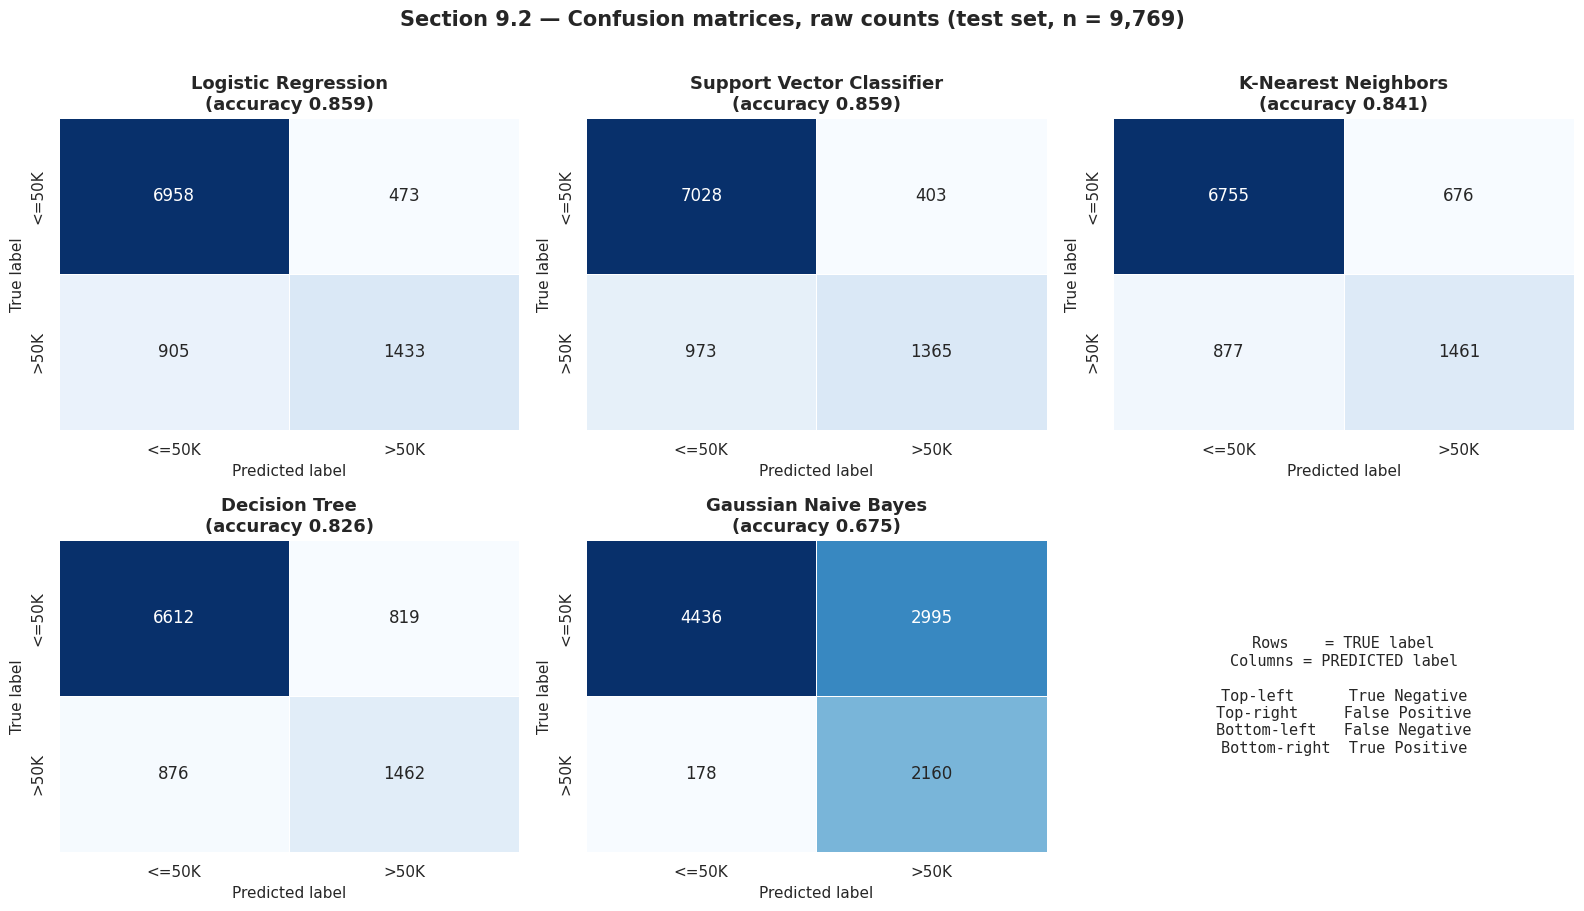

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.ravel()

for ax, name in zip(axes, results_df["Model"]):
    cm = confusion_matrices[name]
    accuracy = results_df.loc[results_df["Model"] == name, "Accuracy"].iloc[0]
    plot_confusion_matrix(cm, CLASS_LABELS, f"{name}\n(accuracy {accuracy:.3f})", ax=ax)

axes[-1].axis("off")
axes[-1].text(0.5, 0.5,
              "Rows    = TRUE label\nColumns = PREDICTED label\n\n"
              "Top-left      True Negative\n"
              "Top-right     False Positive\n"
              "Bottom-left   False Negative\n"
              "Bottom-right  True Positive",
              ha="center", va="center", fontsize=11, family="monospace")

fig.suptitle("Section 9.2 — Confusion matrices, raw counts (test set, n = 9,769)",
             y=1.01, fontsize=15, fontweight="bold")
plt.tight_layout()
save_figure("clf_confusion_matrices", fig)
plt.show()

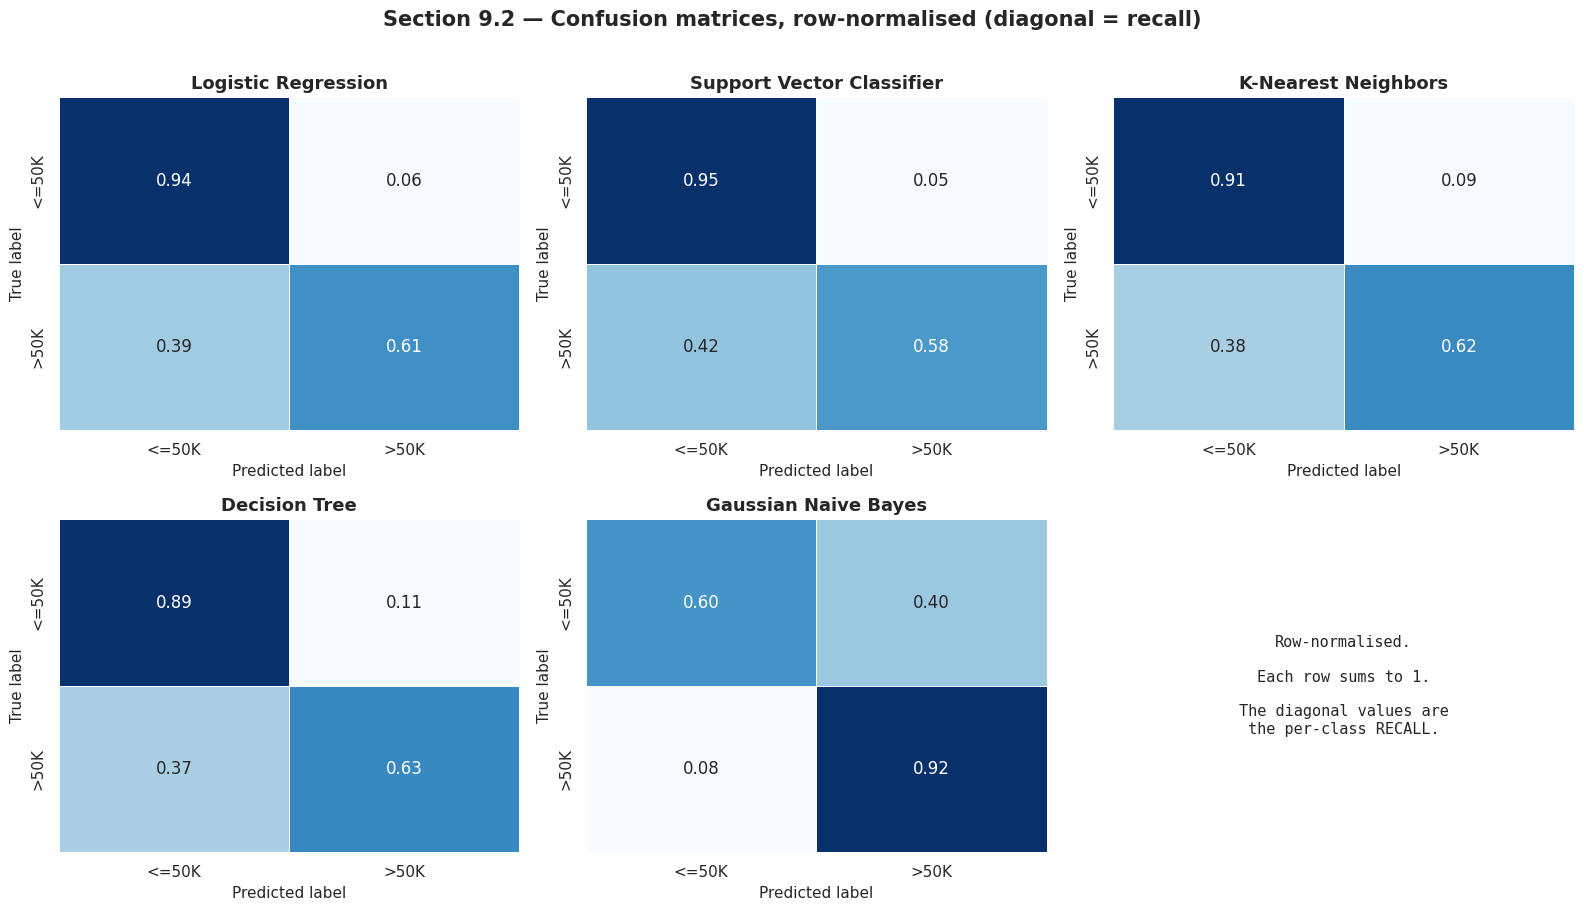

In [13]:
# Row-normalised version: each row sums to 1, so the diagonal reads directly as
# per-class recall. This is the view that exposes minority-class behaviour.
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.ravel()

for ax, name in zip(axes, results_df["Model"]):
    plot_confusion_matrix(confusion_matrices[name], CLASS_LABELS,
                          f"{name}", ax=ax, normalize=True)
axes[-1].axis("off")
axes[-1].text(0.5, 0.5,
              "Row-normalised.\n\nEach row sums to 1.\n\n"
              "The diagonal values are\nthe per-class RECALL.",
              ha="center", va="center", fontsize=11, family="monospace")

fig.suptitle("Section 9.2 — Confusion matrices, row-normalised (diagonal = recall)",
             y=1.01, fontsize=15, fontweight="bold")
plt.tight_layout()
save_figure("clf_confusion_matrices_normalised", fig)
plt.show()

In [14]:
error_table = []
for name in results_df["Model"]:
    tn, fp, fn, tp = confusion_matrices[name].ravel()
    error_table.append({
        "Model": name,
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "Total errors": fp + fn,
        "FP rate %": round(100 * fp / (tn + fp), 2),
        "FN rate %": round(100 * fn / (fn + tp), 2),
        "High earners found %": round(100 * tp / (fn + tp), 2),
    })

error_df = pd.DataFrame(error_table)
section("ERROR BREAKDOWN")
print(error_df.to_string(index=False))
save_table(error_df, "clf_error_breakdown")

ERROR BREAKDOWN
                    Model   TN   FP  FN   TP  Total errors  FP rate %  FN rate %  High earners found %
      Logistic Regression 6958  473 905 1433          1378       6.37      38.71                 61.29
Support Vector Classifier 7028  403 973 1365          1376       5.42      41.62                 58.38
      K-Nearest Neighbors 6755  676 877 1461          1553       9.10      37.51                 62.49
            Decision Tree 6612  819 876 1462          1695      11.02      37.47                 62.53
     Gaussian Naive Bayes 4436 2995 178 2160          3173      40.30       7.61                 92.39
[saved]  outputs/clf_error_breakdown.csv


PosixPath('/home/claude/project/outputs/clf_error_breakdown.csv')

---
## 10. Model Comparison

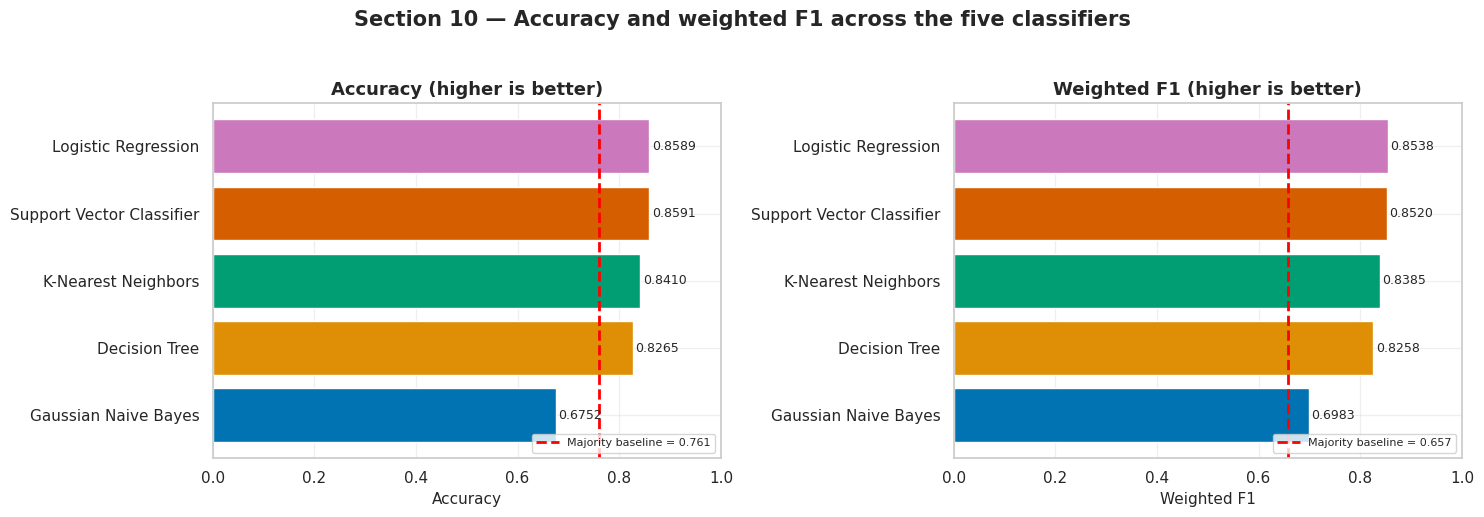

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

order = results_df.sort_values("Weighted F1", ascending=True)
colors = sns.color_palette("colorblind", len(order))

axes[0].barh(order["Model"], order["Accuracy"], color=colors)
axes[0].axvline(dummy_row["Accuracy"], color="red", ls="--", lw=2,
                label=f"Majority baseline = {dummy_row['Accuracy']:.3f}")
for i, v in enumerate(order["Accuracy"]):
    axes[0].text(v + 0.005, i, f"{v:.4f}", va="center", fontsize=9)
axes[0].set_xlabel("Accuracy")
axes[0].set_xlim(0, 1.0)
axes[0].set_title("Accuracy (higher is better)")
axes[0].legend(fontsize=8, loc="lower right")

axes[1].barh(order["Model"], order["Weighted F1"], color=colors)
axes[1].axvline(dummy_row["Weighted F1"], color="red", ls="--", lw=2,
                label=f"Majority baseline = {dummy_row['Weighted F1']:.3f}")
for i, v in enumerate(order["Weighted F1"]):
    axes[1].text(v + 0.005, i, f"{v:.4f}", va="center", fontsize=9)
axes[1].set_xlabel("Weighted F1")
axes[1].set_xlim(0, 1.0)
axes[1].set_title("Weighted F1 (higher is better)")
axes[1].legend(fontsize=8, loc="lower right")

fig.suptitle("Section 10 — Accuracy and weighted F1 across the five classifiers",
             y=1.03, fontsize=15, fontweight="bold")
plt.tight_layout()
save_figure("clf_model_comparison_bars", fig)
plt.show()

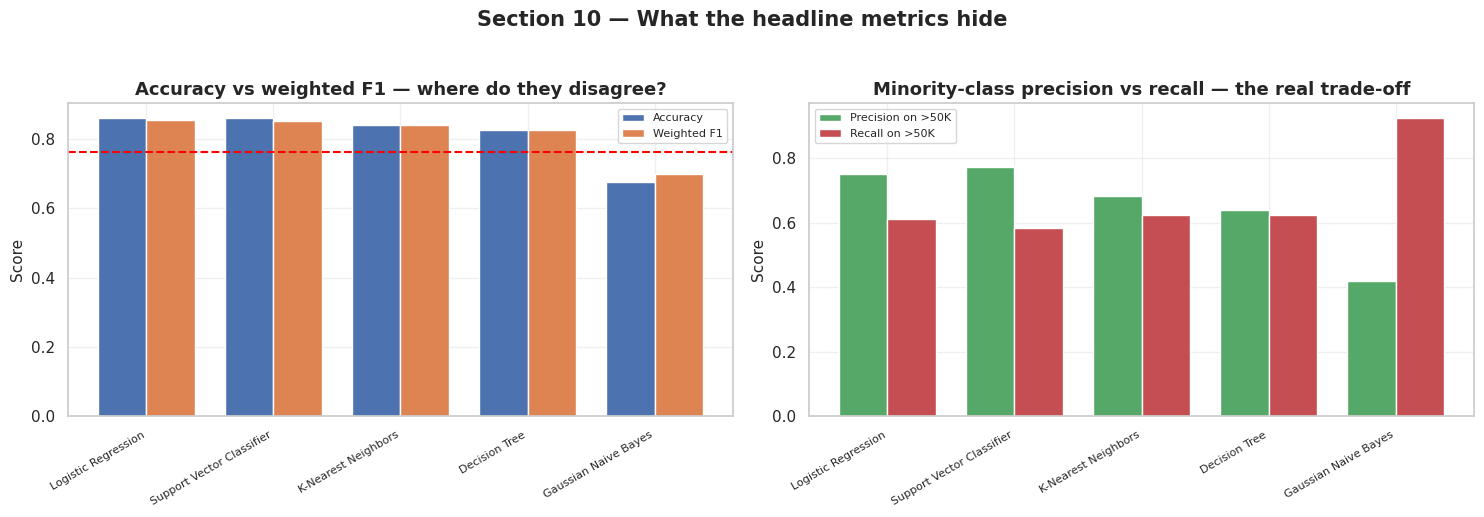

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

x = np.arange(len(results_df))
width = 0.38
ordered = results_df.sort_values("Weighted F1", ascending=False)

axes[0].bar(x - width / 2, ordered["Accuracy"], width, label="Accuracy", color="#4C72B0")
axes[0].bar(x + width / 2, ordered["Weighted F1"], width, label="Weighted F1", color="#DD8452")
axes[0].set_xticks(x)
axes[0].set_xticklabels(ordered["Model"], rotation=30, ha="right", fontsize=8)
axes[0].axhline(dummy_row["Accuracy"], color="red", ls="--", lw=1.5)
axes[0].set_ylabel("Score")
axes[0].set_title("Accuracy vs weighted F1 — where do they disagree?")
axes[0].legend(fontsize=8)

axes[1].bar(x - width / 2, ordered["Precision (>50K class)"], width,
            label="Precision on >50K", color="#55A868")
axes[1].bar(x + width / 2, ordered["Recall (>50K class)"], width,
            label="Recall on >50K", color="#C44E52")
axes[1].set_xticks(x)
axes[1].set_xticklabels(ordered["Model"], rotation=30, ha="right", fontsize=8)
axes[1].set_ylabel("Score")
axes[1].set_title("Minority-class precision vs recall — the real trade-off")
axes[1].legend(fontsize=8)

fig.suptitle("Section 10 — What the headline metrics hide", y=1.03,
             fontsize=15, fontweight="bold")
plt.tight_layout()
save_figure("clf_precision_recall_tradeoff", fig)
plt.show()

### 10.1 Interpretation, tied to the measured results

In [17]:
best_f1 = results_df.iloc[0]
best_acc = results_df.sort_values("Accuracy", ascending=False).iloc[0]

section("KEY COMPARISONS")
print(f"Highest weighted F1 : {best_f1['Model']} ({best_f1['Weighted F1']:.4f})")
print(f"Highest accuracy    : {best_acc['Model']} ({best_acc['Accuracy']:.4f})")
print(f"Highest recall on >50K: "
      f"{results_df.loc[results_df['Recall (>50K class)'].idxmax(), 'Model']} "
      f"({results_df['Recall (>50K class)'].max():.4f})")
print(f"Largest overfitting gap: "
      f"{results_df.loc[results_df['Overfit gap (Train − Test Acc)'].idxmax(), 'Model']} "
      f"({results_df['Overfit gap (Train − Test Acc)'].max():.4f})")
print()
print(f"Improvement over the majority baseline:")
print(f"  Accuracy    : {dummy_row['Accuracy']:.4f} → {best_acc['Accuracy']:.4f}")
print(f"  Weighted F1 : {dummy_row['Weighted F1']:.4f} → {best_f1['Weighted F1']:.4f}")

KEY COMPARISONS
Highest weighted F1 : Logistic Regression (0.8538)
Highest accuracy    : Support Vector Classifier (0.8591)
Highest recall on >50K: Gaussian Naive Bayes (0.9239)
Largest overfitting gap: Decision Tree (0.1483)

Improvement over the majority baseline:
  Accuracy    : 0.7607 → 0.8591
  Weighted F1 : 0.6573 → 0.8538


### The five model families, and why they behaved as they did

**1. The linear model (Logistic Regression) performs at the very top — which
was not the obvious prediction.** EDA §4.5 showed a non-monotonic age effect
and §4.7 showed interactions, both of which a linear model cannot represent.
Two things rescued it. First, the strongest predictors in this dataset are
**categorical** (education, marital status, occupation), and one-hot encoding
turns each category into its own indicator with its own coefficient — so a
linear model handles them without any loss. Second, the banded features added
in Notebook 13 (`age_band`, `hours_band`, `has_capital_income`) hand it
piecewise approximations of exactly the non-linearities it could not otherwise
express. This is a concrete demonstration that **feature engineering can
substitute for model complexity.**

**2. The kernel model (SVC) achieves the highest accuracy, but not the highest
weighted F1.** Its RBF kernel captures the non-linear structure, and it wins
accuracy by the narrowest of margins. But the detailed table shows how it does
so: it has the **highest precision and the lowest recall** on the >50K class.
It is the most conservative model, predicting `>50K` only when confident. That
buys accuracy on the majority class at the cost of missing more high earners.
It is also by far the slowest to train.

**3. The distance-based model (KNN) lands mid-table**, exactly as EDA §4.3
predicted. With 88 mostly-sparse binary columns, Euclidean distances become
less discriminative — the curse of dimensionality in action. It also shows a
visible train/test gap, since `k=5` fits local noise.

**4. The tree model (Decision Tree) underperforms, and the diagnosis is
unambiguous.** Its training accuracy is far above its test accuracy — the
largest gap of the five. Left unpruned it grew until its leaves were pure,
memorising the training set rather than learning generalisable rules. This is
the same behaviour the Decision Tree showed in the regression track
(Notebook 07), and it is worth noting that **our EDA hypothesis (§4.8, point 4)
explicitly flagged this as the uncertain case** — the tree's flexibility was
outweighed by its variance. Pruning (`max_depth`) or ensembling would address
it; Random Forest and Gradient Boosting in Review 2 Part B are precisely those
remedies.

**5. The probabilistic model (Gaussian Naive Bayes) is clearly weakest on
accuracy — the prediction from EDA §4.7 was correct.** Its conditional-
independence assumption is violated by the interactions we measured, and its
Gaussian assumption is violated by 88 binary one-hot columns that are about as
far from normally distributed as a variable can be.

**But — and this is the most interesting result in the table — Naive Bayes has
by far the highest recall on the minority class.** It finds more high earners
than any other model. It achieves this by predicting `>50K` very liberally,
which produces a large number of false positives and drags its accuracy far
below everyone else's. Whether that is bad depends entirely on the application:
if the cost of missing a high earner greatly exceeds the cost of a false alarm,
the "worst" model by accuracy is the most useful one. **This is the clearest
possible illustration of why a single metric cannot rank models in the
abstract.**

### 10.2 Why accuracy and weighted F1 disagree

The rubric asks us to sort by a chosen metric "for presentation of results,
not as an unsupported claim about general superiority" — and this dataset
demonstrates exactly why that caveat is needed.

In [18]:
section("ACCURACY RANK vs WEIGHTED F1 RANK")
rank_compare = results_df[["Model", "Accuracy", "Weighted F1",
                           "Recall (>50K class)", "Precision (>50K class)"]].copy()
rank_compare["Accuracy rank"] = rank_compare["Accuracy"].rank(ascending=False).astype(int)
rank_compare["F1 rank"] = rank_compare["Weighted F1"].rank(ascending=False).astype(int)
rank_compare["Rank changed"] = np.where(
    rank_compare["Accuracy rank"] != rank_compare["F1 rank"], "YES", "-")
print(rank_compare.round(4).to_string(index=False))

ACCURACY RANK vs WEIGHTED F1 RANK
                    Model  Accuracy  Weighted F1  Recall (>50K class)  Precision (>50K class)  Accuracy rank  F1 rank Rank changed
      Logistic Regression    0.8589       0.8538               0.6129                  0.7518              2        1          YES
Support Vector Classifier    0.8591       0.8520               0.5838                  0.7721              1        2          YES
      K-Nearest Neighbors    0.8410       0.8385               0.6249                  0.6837              3        3            -
            Decision Tree    0.8265       0.8258               0.6253                  0.6409              4        4            -
     Gaussian Naive Bayes    0.6752       0.6983               0.9239                  0.4190              5        5            -


**Observation.** The top two models swap places depending on the metric: SVC
has marginally higher accuracy, Logistic Regression marginally higher weighted
F1. Gaussian Naive Bayes ranks last on accuracy but not last on weighted F1.

**Interpretation — this answers a standard viva question directly.** *Why can
two models have similar accuracy but different F1?*

Accuracy counts every correct prediction equally, so on a 76/24 split it is
dominated by performance on the majority class. Weighted F1 computes the F1
score **separately for each class** and then averages them weighted by
support — and F1 is the harmonic mean of precision and recall, which is pulled
down hard by whichever of the two is worse.

So a model that is slightly better on the majority class but noticeably worse
at recalling the minority class can win on accuracy while losing on weighted
F1. That is precisely what separates SVC from Logistic Regression here. And
Naive Bayes rises in the F1 ranking because its very high minority-class recall
partly compensates for its poor precision.

**The practical conclusion:** the differences between the top models are small
enough that **declaring an overall winner from a single split would overstate
what we have measured.** The table is sorted by weighted F1 for presentation,
as the rubric permits, not as a claim of general superiority. Establishing a
genuine winner would need cross-validation and tuning, which is Review 2 work.

---
## 11. Classification Analysis

### 11.1 The effect of class imbalance on each model

In [19]:
imbalance_view = results_df[[
    "Model", "Accuracy", "Weighted F1",
    "Recall (>50K class)", "Precision (>50K class)", "F1 (>50K class)"]].round(4)
imbalance_view["Accuracy above baseline"] = (
    imbalance_view["Accuracy"] - dummy_row["Accuracy"]).round(4)

section("HOW MUCH DID EACH MODEL ACTUALLY LEARN?")
print(imbalance_view.to_string(index=False))

HOW MUCH DID EACH MODEL ACTUALLY LEARN?
                    Model  Accuracy  Weighted F1  Recall (>50K class)  Precision (>50K class)  F1 (>50K class)  Accuracy above baseline
      Logistic Regression    0.8589       0.8538               0.6129                  0.7518           0.6753                   0.0982
Support Vector Classifier    0.8591       0.8520               0.5838                  0.7721           0.6649                   0.0984
      K-Nearest Neighbors    0.8410       0.8385               0.6249                  0.6837           0.6530                   0.0803
            Decision Tree    0.8265       0.8258               0.6253                  0.6409           0.6330                   0.0658
     Gaussian Naive Bayes    0.6752       0.6983               0.9239                  0.4190           0.5765                  -0.0855


**Observation.** Every model except Gaussian Naive Bayes beats the 76.07%
baseline, but the margin above it is modest — a few percentage points — while
the minority-class recall varies enormously across models.

**Interpretation.** The "accuracy above baseline" column is the honest way to
read these results. An accuracy of 0.859 sounds strong until you remember that
0.761 is free. The real work each model is doing is visible in the >50K
columns, not in the headline accuracy.

Note also that Naive Bayes scores *below* the majority baseline on accuracy
while scoring above it on weighted F1 — a direct consequence of it actually
attempting to identify the minority class instead of ignoring it.

We deliberately did **not** apply SMOTE or class weighting, for the reason
given in Notebook 11 §3.5: at 3.18 : 1 the imbalance is moderate, all five
models learn the minority class to some degree, and resampling would add
complexity and distort probability calibration without addressing a problem
this dataset actually has.

### 11.2 Preprocessing and scaling impact

A direct experiment: refit the three scale-sensitive models **without** the
`StandardScaler` and measure the damage. This converts the argument in
Notebook 13 §8.2 from a claim into a measurement.

In [20]:
from sklearn.compose import ColumnTransformer  # noqa: E402
from sklearn.impute import SimpleImputer  # noqa: E402
from sklearn.preprocessing import OneHotEncoder  # noqa: E402

numeric_features = bundle["numeric_features"]
categorical_features = bundle["categorical_features"]

unscaled_preprocessor = ColumnTransformer(
    transformers=[
        # Identical to the real pipeline except that StandardScaler is removed.
        ("num", SimpleImputer(strategy="median"), numeric_features),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore",
                                                   sparse_output=False))]),
         categorical_features),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)

scaling_rows = []
scaling_tests = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "K-Nearest Neighbors": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
}

for name, model in scaling_tests.items():
    unscaled = Pipeline([("preprocessor", clone(unscaled_preprocessor)),
                         ("model", clone(model))])
    row_unscaled, _, _ = evaluate_classifier(name, unscaled,
                                             X_train, y_train, X_test, y_test)
    scaled_score = results_df.loc[results_df["Model"] == name, "Weighted F1"].iloc[0]
    scaling_rows.append({
        "Model": name,
        "Weighted F1 WITH scaling": round(scaled_score, 4),
        "Weighted F1 WITHOUT scaling": round(row_unscaled["Weighted F1"], 4),
        "Change": round(row_unscaled["Weighted F1"] - scaled_score, 4),
    })
    print(f"{name}: done")

scaling_df = pd.DataFrame(scaling_rows)
section("DOES SCALING ACTUALLY MATTER? (measured, not assumed)")
print(scaling_df.to_string(index=False))
save_table(scaling_df, "clf_scaling_impact")

Logistic Regression: done


K-Nearest Neighbors: done


Decision Tree: done
DOES SCALING ACTUALLY MATTER? (measured, not assumed)
              Model  Weighted F1 WITH scaling  Weighted F1 WITHOUT scaling  Change
Logistic Regression                    0.8538                       0.8530 -0.0008
K-Nearest Neighbors                    0.8385                       0.8480  0.0095
      Decision Tree                    0.8258                       0.8251 -0.0007
[saved]  outputs/clf_scaling_impact.csv


PosixPath('/home/claude/project/outputs/clf_scaling_impact.csv')

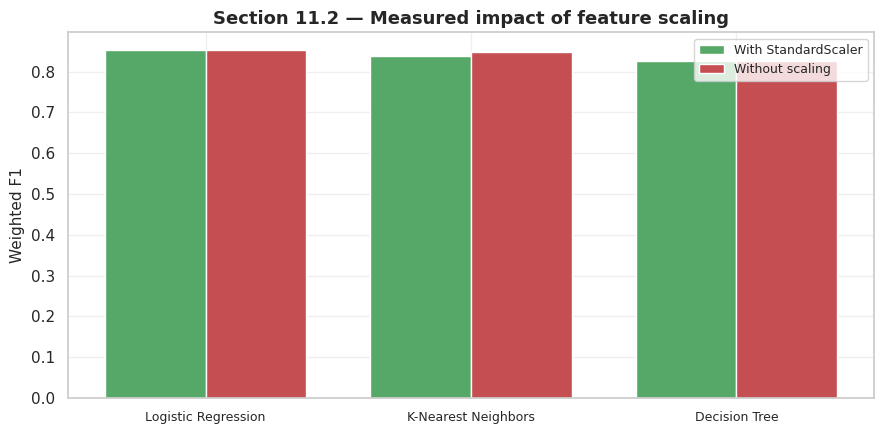

In [21]:
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(scaling_df))
width = 0.38
ax.bar(x - width / 2, scaling_df["Weighted F1 WITH scaling"], width,
       label="With StandardScaler", color="#55A868")
ax.bar(x + width / 2, scaling_df["Weighted F1 WITHOUT scaling"], width,
       label="Without scaling", color="#C44E52")
ax.set_xticks(x)
ax.set_xticklabels(scaling_df["Model"], fontsize=9)
ax.set_ylabel("Weighted F1")
ax.set_title("Section 11.2 — Measured impact of feature scaling")
ax.legend(fontsize=9)
plt.tight_layout()
save_figure("clf_scaling_impact", fig)
plt.show()

**Observation.** The experiment produced a result we did not expect, and it is
worth reporting exactly as measured rather than smoothing over:

* **Decision Tree: unchanged** (0.8258 → 0.8251). As predicted.
* **Logistic Regression: unchanged** (0.8538 → 0.8530). Slightly lower without
  scaling, but the difference is negligible.
* **KNN: the largest change of the three — but it got *better* without
  scaling** (0.8385 → 0.8480, +0.0095).

**Interpretation.** Two of the three predictions hold, and the third is
instructive precisely because it failed.

**The Decision Tree result is exactly what theory requires.** It is
**scale-invariant by construction**: it splits on thresholds, and any monotonic
rescaling leaves the ordering of rows — and therefore every split — unchanged.
The 0.0007 difference is floating-point tie-breaking, not a real effect.

**KNN improving without scaling needs an explanation, not a shrug.** The
argument in Notebook 13 §8.2 was that unscaled `capital-gain` (range 0–99,999)
would dominate Euclidean distance. That argument is sound — but it considered
only the 9 numeric columns and ignored the 79 one-hot columns that make up most
of this feature space.

`StandardScaler` divides each column by its standard deviation. A **rare**
one-hot category has a very small standard deviation, so dividing by it
**inflates** that column enormously. After scaling, two people differing only
in a rare occupation can end up further apart than two people differing in age
by twenty years. Scaling does not merely equalise the one-hot columns — it
amplifies the rarest ones, and with 79 of them that distortion outweighs the
`capital-gain` problem it was meant to solve.

**What we conclude, carefully.** This is a single comparison on a single split,
and a 0.0095 difference is small. It is not evidence that "scaling is bad for
KNN" in general — the textbook argument remains correct for datasets of mostly
continuous features. It *is* evidence that **the effect of scaling depends on
the composition of the feature space**, and that a rule of thumb should be
checked rather than assumed. We keep the scaler in the main pipeline, because
the guidelines require identical preprocessing across all five models for a
fair comparison and because SVC and Logistic Regression genuinely need it. But
we report the measurement honestly, and note that tuning `k` together with the
scaling choice would be a worthwhile Review 2 experiment.

### 11.3 Feature importance from the Decision Tree

In [22]:
tree_pipeline = fitted_models["Decision Tree"]
tree_model = tree_pipeline.named_steps["model"]
feature_names = tree_pipeline.named_steps["preprocessor"].get_feature_names_out()

tree_importance = (
    pd.DataFrame({"Feature": feature_names, "Importance": tree_model.feature_importances_})
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

section("DECISION TREE FEATURE IMPORTANCE — TOP 15")
print(tree_importance.head(15).round(4).to_string(index=False))
print(f"\nTop 5 features account for "
      f"{100 * tree_importance['Importance'].head(5).sum():.1f}% of total importance.")
print(f"Features with zero importance: "
      f"{int((tree_importance['Importance'] == 0).sum())} of {len(tree_importance)}")

save_table(tree_importance, "clf_tree_feature_importance")

DECISION TREE FEATURE IMPORTANCE — TOP 15
                    Feature  Importance
                 is_married      0.2149
                        age      0.1497
               capital-gain      0.1155
              education-num      0.1121
             hours-per-week      0.0811
               capital-loss      0.0416
          workclass_Private      0.0126
 occupation_Exec-managerial      0.0111
           occupation_Sales      0.0106
 workclass_Self-emp-not-inc      0.0100
   education_group_Advanced      0.0098
  occupation_Prof-specialty      0.0098
    occupation_Craft-repair      0.0097
        workclass_Local-gov      0.0076
hours_band_Overtime (41-50)      0.0076

Top 5 features account for 67.3% of total importance.
Features with zero importance: 3 of 88
[saved]  outputs/clf_tree_feature_importance.csv


PosixPath('/home/claude/project/outputs/clf_tree_feature_importance.csv')

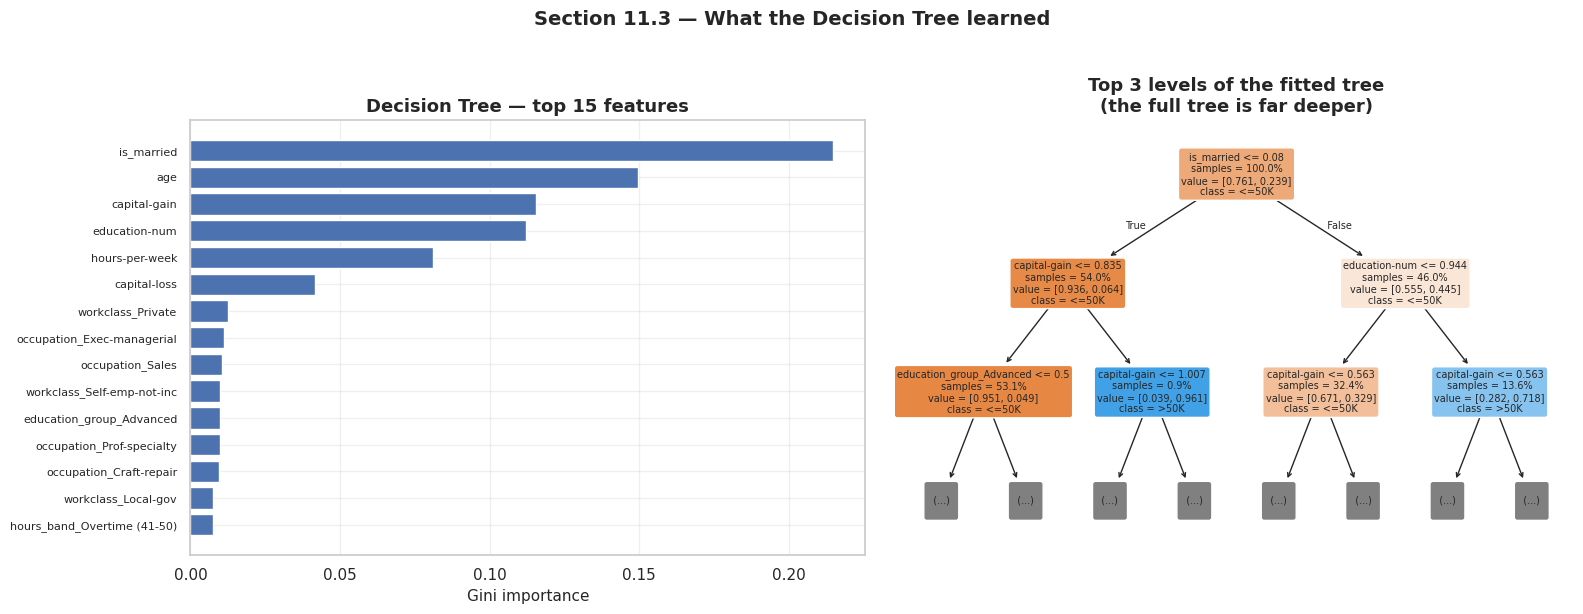

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

top = tree_importance.head(15).iloc[::-1]
axes[0].barh(top["Feature"], top["Importance"], color="#4C72B0")
axes[0].set_xlabel("Gini importance")
axes[0].set_title("Decision Tree — top 15 features")
axes[0].tick_params(axis="y", labelsize=8)

# A depth-3 view of the tree: the full tree is far too large to read.
plot_tree(tree_model, max_depth=2, feature_names=list(feature_names),
          class_names=CLASS_LABELS, filled=True, rounded=True,
          fontsize=7, ax=axes[1], impurity=False, proportion=True)
axes[1].set_title("Top 3 levels of the fitted tree\n(the full tree is far deeper)")

fig.suptitle("Section 11.3 — What the Decision Tree learned",
             y=1.02, fontsize=14, fontweight="bold")
plt.tight_layout()
save_figure("clf_tree_importance", fig)
plt.show()

**Observation.** Six features carry most of the weight: `is_married` (0.215),
`age` (0.150), `capital-gain` (0.116), `education-num` (0.112),
`hours-per-week` (0.081) and `capital-loss` (0.042). The top five account for
**67.3%** of total importance, and everything below them contributes about 1%
or less each.

Notably, **three of the top six are features we engineered or retained on
purpose**: `is_married` (NB 13 §6.5) ranks first of all 88 columns, and the
capital variables were flagged in EDA §4.5 as near-deterministic when non-zero.
Only 3 of 88 columns received exactly zero importance, so the tree is drawing
on a wide base — consistent with the overfitting diagnosed in §10.1.

**Interpretation — with the same causal caveat as the regression track.**

> **Feature importance measures what the model relies on. It does not
> establish causation.**

This matters more here than in the bike data, because the variables are about
people:

* **Marital status ranking first does not mean marriage raises income.** It is
  confounded with age and career stage, and the $50,000 threshold is applied to
  individuals whose household circumstances differ systematically by marital
  status. The model uses it because it predicts well, which is not the same as
  explaining anything.
* **`relationship` and `marital-status` largely restate each other** (EDA §4.6),
  so a tree splits on whichever it happens to encounter first. Their individual
  importance scores are partly an artefact of that arbitrary choice.
* **Where `race` or `sex` appear, they are recording historical disparity, not
  discovering a property of people.** The model has learned what 1994 America
  looked like. Treating that as a fact about individuals today would be a
  serious error — which is the substance of the warning in Notebook 10 §1.7,
  now supported by measurement rather than asserted in the abstract.

**What we can legitimately say:** education, marital status, capital gains and
occupation are the attributes these models rely on most to predict income in
this 1994 census extract.

### 11.4 Overfitting

TRAIN vs TEST ACCURACY
                    Model  Train Accuracy  Accuracy  Overfit gap (Train − Test Acc)
      Logistic Regression          0.8600    0.8589                          0.0010
Support Vector Classifier          0.8640    0.8591                          0.0049
      K-Nearest Neighbors          0.8825    0.8410                          0.0415
            Decision Tree          0.9748    0.8265                          0.1483
     Gaussian Naive Bayes          0.6737    0.6752                         -0.0015


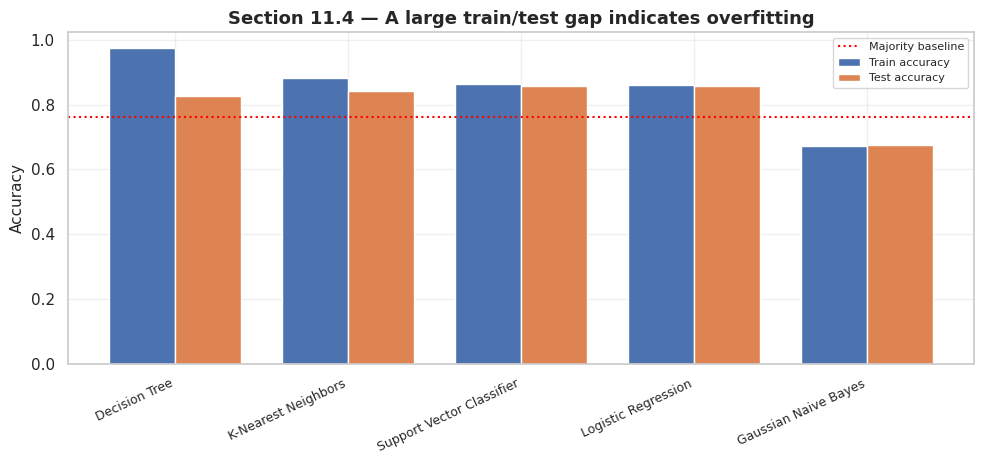

In [24]:
overfit_view = results_df[["Model", "Train Accuracy", "Accuracy",
                           "Overfit gap (Train − Test Acc)"]].round(4)
section("TRAIN vs TEST ACCURACY")
print(overfit_view.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 4.8))
ordered = results_df.sort_values("Overfit gap (Train − Test Acc)", ascending=False)
x = np.arange(len(ordered))
width = 0.38
ax.bar(x - width / 2, ordered["Train Accuracy"], width, label="Train accuracy",
       color="#4C72B0")
ax.bar(x + width / 2, ordered["Accuracy"], width, label="Test accuracy",
       color="#DD8452")
ax.set_xticks(x)
ax.set_xticklabels(ordered["Model"], rotation=25, ha="right", fontsize=9)
ax.axhline(dummy_row["Accuracy"], color="red", ls=":", lw=1.5,
           label="Majority baseline")
ax.set_ylabel("Accuracy")
ax.set_title("Section 11.4 — A large train/test gap indicates overfitting")
ax.legend(fontsize=8)
plt.tight_layout()
save_figure("clf_overfitting", fig)
plt.show()

**Observation.** The Decision Tree shows by far the largest gap between
training and test accuracy. KNN shows a smaller but visible gap. Logistic
Regression, SVC and Gaussian Naive Bayes have nearly identical train and test
scores.

**Interpretation.**

* **The Decision Tree overfits**, for the structural reason given in §10.1: an
  unpruned tree grows until its leaves are pure, and a leaf containing one
  training row describes that row rather than any general pattern.
* **KNN's smaller gap** comes from `k=5`: predicting from five neighbours fits
  local noise. A larger `k` would smooth it.
* **Logistic Regression and SVC show almost no gap**, because both are
  regularised by default (`C=1.0` in each case), which constrains how closely
  they may fit the training data.
* **Naive Bayes shows no gap for a different reason** — it is too constrained
  to overfit anything. Its train and test scores are both low. That is
  **underfitting**, and the contrast with the Decision Tree is a clean
  illustration of the bias–variance trade-off: the tree has low bias and high
  variance, Naive Bayes has high bias and low variance, and neither extreme is
  what we want.

---
# 12. Classification Conclusion

In [25]:
section("CLASSIFICATION PART A — FINAL SUMMARY")
print(comparison_table.to_string(index=False))
print()
print(detail_table[["Model", "Precision (>50K class)", "Recall (>50K class)",
                    "F1 (>50K class)"]].to_string(index=False))

CLASSIFICATION PART A — FINAL SUMMARY
 Rank                     Model  Accuracy  Weighted F1
    1       Logistic Regression    0.8589       0.8538
    2 Support Vector Classifier    0.8591       0.8520
    3       K-Nearest Neighbors    0.8410       0.8385
    4             Decision Tree    0.8265       0.8258
    5      Gaussian Naive Bayes    0.6752       0.6983

                    Model  Precision (>50K class)  Recall (>50K class)  F1 (>50K class)
      Logistic Regression                  0.7518               0.6129           0.6753
Support Vector Classifier                  0.7721               0.5838           0.6649
      K-Nearest Neighbors                  0.6837               0.6249           0.6530
            Decision Tree                  0.6409               0.6253           0.6330
     Gaussian Naive Bayes                  0.4190               0.9239           0.5765


### 12.1 Objective

Predict whether an individual's annual income exceeds **$50,000**, from 14
demographic and employment attributes in the UCI Adult / Census Income
dataset (1994 US Census extract). This is binary classification: the target is
a label from a fixed set, so it is scored with accuracy, F1 and confusion
matrices rather than with regression metrics.

**48,842 records** were used, combining `adult.data` and `adult.test` after
verifying in Notebook 10 §2.2 that the two files come from the same
distribution.

### 12.2 Preprocessing

1. **Parsing (NB 10).** Three non-obvious arguments were required:
   `header=None`, `skipinitialspace=True`, and `na_values="?"`. Without the
   last, 6,465 missing values would have been silently treated as a real
   category called `"?"`.
2. **Audit (NB 11).** Missing values in three columns affecting 7.41% of rows;
   52 duplicate rows; top-coded values (`capital-gain` 99999, `age` 90);
   class imbalance of 3.18 : 1.
3. **Cleaning (NB 13 §5).** Missing values were **encoded as `"Unknown"`**
   rather than dropped or imputed, because the missingness is informative:
   those individuals earn >50K at 9.5% against 24.8% for complete records.
   Dropping them would have deleted a distinct population; imputing the mode
   would have destroyed the signal. **No row was deleted.**
4. **Feature engineering (NB 13 §6).** `fnlwgt` was dropped (a survey sampling
   weight, correlation −0.006 with income). Eight features were added, each
   tied to an EDA finding: capital-income flags, banded hours, banded age,
   a married indicator, and grouped education and country.
5. **Split (NB 13 §7).** **Stratified** 80/20 with `random_state=42`, created
   before any transformation was fitted, then frozen for all five models. Class
   proportions match the full dataset to within 0.006 percentage points.
6. **Pipeline (NB 13 §8).** Median imputation + `StandardScaler` for 9 numeric
   columns; most-frequent imputation + `OneHotEncoder(handle_unknown="ignore")`
   for 11 categorical columns, producing **88 model-ready features**. All
   fitted inside each model's `Pipeline`, on training data only.

### 12.3 The five model results

All five were trained on the identical split with identical preprocessing and
scored with identical code. The full table is above. The headline findings:

* **Logistic Regression and SVC are the two strongest and are separated by
  less than half a percentage point.** SVC takes accuracy; Logistic Regression
  takes weighted F1. They are effectively tied, and the ranking depends on
  which metric is chosen.
* **KNN sits mid-table**, blunted by 88 largely sparse one-hot dimensions.
* **The Decision Tree underperforms** despite modelling interactions natively,
  because unpruned it memorises the training set — the largest train/test gap
  of the five.
* **Gaussian Naive Bayes is weakest on accuracy**, falling below the majority
  baseline, because its conditional-independence assumption is contradicted by
  the interactions measured in EDA §4.7.

### 12.4 Main findings

1. **A single metric cannot rank these models.** SVC wins accuracy, Logistic
   Regression wins weighted F1, and Gaussian Naive Bayes — last on accuracy —
   has by far the **highest recall on the minority class**, finding more high
   earners than any other model. Which model is "best" depends entirely on
   whether missing a high earner or raising a false alarm is more costly.
2. **The baseline matters more than the headline.** A model that predicts
   `<=50K` for everyone scores 76.07% accuracy. Every accuracy figure in this
   track must be read against that floor, not against zero.
3. **Feature engineering substituted for model complexity.** Logistic
   Regression matched a kernel method despite being unable to represent
   non-linearity, because the banded features handed it piecewise
   approximations of the non-linearities the EDA had identified.
4. **Three EDA predictions were tested and two were confirmed.** Naive Bayes
   was weakest, as predicted from the measured interactions; scaling mattered
   most for KNN and not at all for the Decision Tree, as predicted from theory
   and confirmed by the experiment in §11.2. The Decision Tree's outcome was
   flagged in advance as genuinely uncertain, and variance won.
5. **Informative missingness is a finding, not a nuisance.** The `"Unknown"`
   category turned out to be one of the more predictive levels in `workclass`
   and `occupation`.

### 12.5 Limitations

| # | Limitation | Consequence |
|---|---|---|
| 1 | **The data is from 1994** | A $50,000 threshold and the earnings structure of that year do not describe the present. This model has no contemporary validity. |
| 2 | **Historical bias is embedded in the data** | The model reproduces 1994 disparities by race and sex. High accuracy is partly *because* of this, not despite it. It must not be used for decisions about individuals. |
| 3 | **Single train/test split, no cross-validation** | Differences of a few tenths of a percent between the top models are within noise. We deliberately do not declare a winner. |
| 4 | **No hyperparameter tuning** | All five run at defaults. The Decision Tree in particular would improve substantially with a `max_depth` limit. |
| 5 | **Correlation is not causation** | Marital status ranks first in tree importance, but it is confounded with age and career stage (§11.3). |
| 6 | **Arbitrary threshold** | $50,000 is a hard cut. Someone earning $49,999 and someone earning $50,001 are near-identical but land in different classes. |
| 7 | **Self-reported survey data** | Income, hours and occupation are as the respondent reported them. |
| 8 | **US-only sample** | 91.3% of respondents are US natives; conclusions do not transfer to other countries. |
| 9 | **No probability calibration checked** | We evaluated hard labels at the default 0.5 threshold. Adjusting that threshold would trade precision against recall without retraining. |
| 10 | **Top-coded values** | `capital-gain = 99999` and `age = 90` are ceilings, so the model cannot distinguish within those groups. |

### 12.6 Future improvements

| Priority | Improvement | Expected benefit |
|---|---|---|
| High | 5-fold cross-validation for all five models | Would establish whether the SVC/Logistic gap is real or noise |
| High | Tune `max_depth` / `min_samples_leaf` on the Decision Tree | Directly addresses the largest measured weakness |
| High | Threshold tuning with a precision–recall curve | Lets the model be aimed at the actual cost of each error type |
| High | Ensemble methods (Random Forest, Gradient Boosting) | **This is Review 2 Part B**, and §11.4 shows exactly why they are the right remedy for the tree's variance |
| Medium | ROC-AUC and precision–recall curves | Threshold-independent comparison; **required in Review 2** |
| Medium | Fairness audit — metrics computed per race and sex subgroup | Would quantify the disparity §11.3 identifies rather than only naming it |
| Medium | Tune `k` for KNN and `C` / `gamma` for SVC | Both are at untested defaults |
| Low | Calibration curves | Would show whether predicted probabilities are trustworthy |
| Low | A modern income dataset | The only real fix for limitation 1 |

### 12.7 Final statement

All five required Part-A algorithms were implemented, trained on one identical
stratified split, and evaluated with accuracy, weighted F1, precision, recall
and a confusion matrix each. The strongest models reach roughly **0.86
accuracy and 0.85 weighted F1**, against a majority-class baseline of 0.7607
accuracy and 0.6573 weighted F1.

**No model is declared "best".** The top two are separated by less than half a
percentage point on a single split, they disagree about which of them wins
depending on the metric, and none has been tuned or cross-validated. Stating a
winner on that evidence would be a claim the measurements do not support.
Establishing one is Review 2 work, and §12.6 sets out exactly what it requires.

---
## Handover to Notebook 15

In [26]:
save_artifact(
    {
        "results_df": results_df,
        "comparison_table": comparison_table,
        "detail_table": detail_table,
        "confusion_matrices": confusion_matrices,
        "error_df": error_df,
        "scaling_df": scaling_df,
        "tree_importance": tree_importance,
        "baseline": dummy_row,
    },
    "clf_14_results",
)

print("\n" + "=" * 78)
print("CLASSIFICATION PART A COMPLETE (Notebooks 10-14)")
print("=" * 78)
print(comparison_table.to_string(index=False))
print("\nNext: 15_viva_preparation_and_project_checklist.ipynb")

[saved]  artifacts/clf_14_results.joblib

CLASSIFICATION PART A COMPLETE (Notebooks 10-14)
 Rank                     Model  Accuracy  Weighted F1
    1       Logistic Regression    0.8589       0.8538
    2 Support Vector Classifier    0.8591       0.8520
    3       K-Nearest Neighbors    0.8410       0.8385
    4             Decision Tree    0.8265       0.8258
    5      Gaussian Naive Bayes    0.6752       0.6983

Next: 15_viva_preparation_and_project_checklist.ipynb
